# Financial Time Series

       The only reason for time is so that everything doesn’t happen at once.
                                                                — Albert Einstein

Focuses on the following topics:
* Pandas introduction
* Pandas + Internet
* High frequency data

In [32]:
# import packages

import numpy as np, pandas as pd, math
import pandas_datareader.data as web
import yfinance as yf
import matplotlib as mpl
import matplotlib.pyplot as plt
from urllib.request import urlretrieve

## Basic Analytics
* pandas basics skipped

In [7]:
df = (
    pd.DataFrame(
        np.random.standard_normal((9, 4))
        .round(6)
    )
)
df.columns = [['No1', 'No2', 'No3', 'No4']]

# add date column
df.index = pd.date_range('2015-1-1', periods=9, freq='ME')

df.head()

,No1,No2,No3,No4
2015-01-31,0.478687,-0.825691,1.905761,0.619968
2015-02-28,0.064815,-0.586965,0.776132,-1.552666
2015-03-31,-0.328621,1.337698,0.400914,-1.592705
2015-04-30,0.543072,-0.237967,-0.604296,-0.048910
2015-05-31,-0.554360,-0.753578,0.952444,-0.209488


In [8]:
# column wise analytical functions
df.mean()

df.sum()

df.describe()

,No1,No2,No3,No4
count,9.000000,9.000000,9.000000,9.000000
mean,0.251648,0.396881,0.472924,-0.148321
std,0.718345,1.228269,0.697681,1.001254
min,-0.846001,-0.825691,-0.604296,-1.592705
25%,-0.328621,-0.635173,0.108933,-0.423574
50%,0.478687,-0.237967,0.400914,-0.209488
75%,0.620446,1.378528,0.776132,0.619968
max,1.283286,2.227688,1.905761,1.395533


<Axes: >

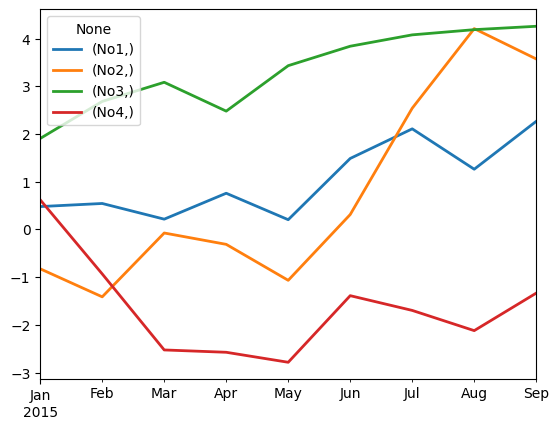

In [9]:
# simple visualization with pandas analytical functions

%matplotlib inline
df.cumsum().plot(lw=2.0)

## Application To Financial Data

In [18]:
DAX = yf.download("^GDAXI", start = "2000-01-01", end = "2014-12-31", progress = False, auto_adjust = False)
DAX.columns = DAX.columns.get_level_values('Price') # remove multi-index

DAX.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2000-01-03,6750.759766,6750.759766,7159.330078,6720.870117,6961.720215,43072500
2000-01-04,6586.950195,6586.950195,6755.359863,6510.459961,6747.240234,46678400
2000-01-05,6502.069824,6502.069824,6585.850098,6388.910156,6585.850098,52682800
2000-01-06,6474.919922,6474.919922,6539.310059,6402.629883,6501.450195,41180600
2000-01-07,6780.959961,6780.959961,6791.529785,6470.140137,6489.939941,56058900


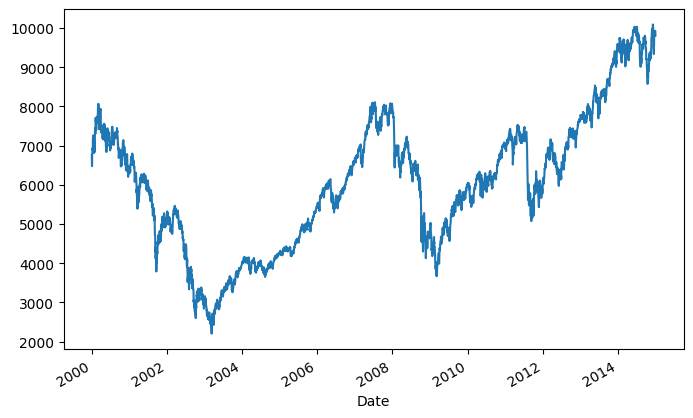

In [ ]:
# simple plot: historical data
DAX['Close'].plot(figsize=(8, 5));

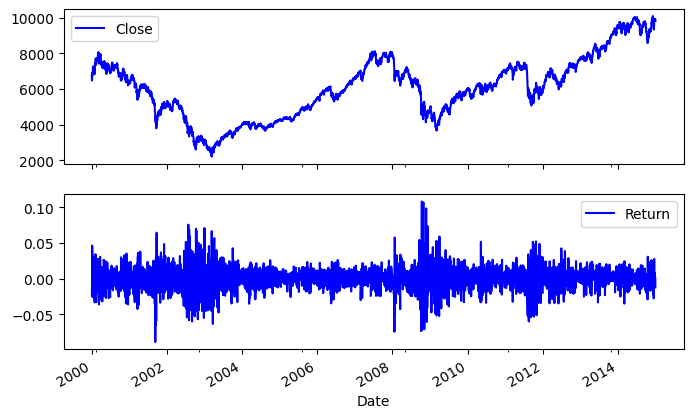

In [ ]:
# calculate daily logarithmic return plot
DAX['Return'] = np.log(DAX['Close'] / DAX['Close'].shift(1))

DAX[['Close', 'Return']].plot(
    subplots=True,
    style='b',
    figsize=(8, 5)
);

#Logarithmic returns have several advantages:
#Time Additivity: Log returns can be summed over time to get total return over a period.
#Symmetry: They treat percentage increases and decreases more symmetrically.
#Better for modeling: Many financial models assume asset prices follow a log-normal distribution.

# log returns are directly related to volatility: they are the input to volatility calculations (more relavant for options traders)

<Axes: xlabel='Date'>

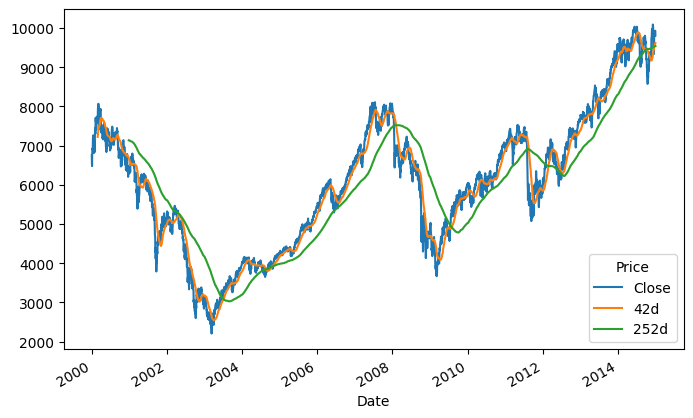

In [26]:
# unlike options traders, stock traders may be more interested in moving averages

DAX['42d'] = DAX['Close'].rolling(window = 42).mean()
DAX['252d'] = DAX['Close'].rolling(window = 252).mean()

DAX[['Close', '42d', '252d']].plot(figsize=(8, 5))

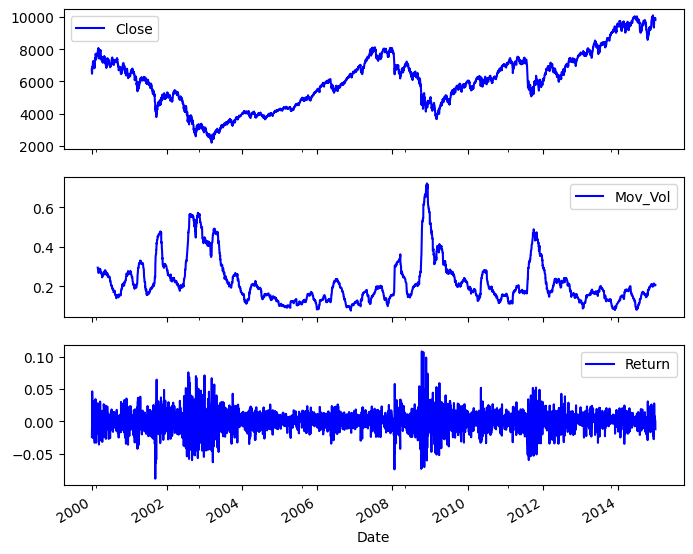

In [29]:
# we can calculate the moving historical volatility as below
DAX['Mov_Vol'] = DAX['Return'].rolling(window = 42).std() * math.sqrt(252)

DAX[['Close', 'Mov_Vol', 'Return']].plot(
    subplots=True,
    style='b',
    figsize=(8, 7)
);

## High Frequency Data

* The Norwegian online broker Netfonds provides tick data for a multitude of stocks, in particular for American names. The web-based API has basically the following format:

In [ ]:
# link
url1 = 'http://hopey.netfonds.no/posdump.php?'
url2 = 'date=%s%s%s&paper=AAPL.O&csv_format=csv'
url = url1 + url2

# parameters of interest
year = '2014'
month = '09'
days = ['22', '23', '24', '25']

# load data
all_data = []  # Use a list to collect DataFrames
for day in days:
    print("Trying URL:", url % (year, month, day))  # 🔍 Add this line
    df = pd.read_csv(
        url % (year, month, day),
        index_col=0,
        header=0,
        parse_dates=True
    )
    all_data.append(df)

# Concatenate all collected DataFrames at once
AAPL = pd.concat(all_data)
AAPL.columns = ['bid', 'bdepth', 'bdeptht', 'offer', 'odepth', 'odeptht']

AAPL.head()

# ticker data is not publicly available hence this will crash, tried debugging but failed; would need an api like polygon.io

Trying URL: http://hopey.netfonds.no/posdump.php?date=20140922&paper=AAPL.O&csv_format=csv


URLError: <urlopen error [Errno 8] nodename nor servname provided, or not known>

## Conclusions
* Financial time series data is one of the most common and important forms of data in finance. The library pandas is generally the tool of choice when it comes to working
with such data sets
* Modeled after the data.frame class of R, the pandas DataFrame class provides a wealth of attributes and methods to attack almost any kind of (financial) analytics problem you might face. Convenience is another benefit of using pandas: even if you might be able to generate the same result by using NumPy and/or matplotlib only, pandas generally has some neat shortcuts based on a powerful and flexible API